# Causal Effect of Hybrid Powertrain on Fuel Consumption

**Data**: EPA Fuel Economy dataset, ~50k vehicles (raw MY1984-2027; analysis
restricted to MY1998-2026)

**Research question**: What is the causal effect of a hybrid powertrain on **fuel
consumption**, controlling for vehicle characteristics?

**Outcome metric**: gallons per 100 miles (GP100 = 100 / MPG), i.e. how much fuel
a vehicle burns per unit distance. This is the right scale for fuel savings.
MPG is a *reciprocal* of consumption, so differences in MPG systematically
exaggerate savings at the high end ("the MPG illusion"). We report MPG only as a
familiar reference in the naive comparison.

**Identification strategy**: hybrid powertrain is a binary treatment. Confounders
include engine displacement, cylinder count, vehicle class, drive type,
manufacturer, and model year. Because hybrids and gasoline vehicles overlap only
in part of the covariate space, the credible estimand is the effect in the
**overlap (common-support) population**, not a whole-fleet ATE. Matching-based
estimators (PSM, within-model) target the ATT.

**Why this is not trivial**: hybrids are systematically different from gasoline
vehicles - they cluster in specific segments (midsize sedans, compact SUVs), tend
to have smaller displacement, and appear in later model years. A naive mean
comparison conflates the treatment effect with selection into treatment.

**Two corrections relative to a naive pipeline**, worth stating up front:
1. Observations are **not independent** - the EPA file has many trim/drive rows
   per vehicle and the same nameplate recurs across years. We deduplicate exact
   spec rows and use **cluster-robust inference** (clustered by make+base model)
   for every reported CI except the causal forest.
2. Nuisance models for AIPW and the T-learner are **cross-fitted**, so in-sample
   overfitting does not shrink residuals and fake-narrow the intervals.

## 1. Data loading and preparation

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import GroupKFold, cross_val_predict
from catboost import CatBoostRegressor, CatBoostClassifier
from doubleml import DoubleMLClusterData, DoubleMLIRM
from econml.dml import CausalForestDML

# Hide library FutureWarnings only.
warnings.simplefilter('ignore', FutureWarning)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

GREEN, BLUE, GREY, RED = '#1D9E75', '#378ADD', '#B4B2A9', '#E24B4A'


# Shared CatBoost settings for every nuisance model.
def cb_reg(seed=42, iters=200):
    return CatBoostRegressor(iterations=iters, depth=5, learning_rate=0.05,
                             verbose=0, random_seed=seed)


def cb_clf(seed=42, iters=200):
    return CatBoostClassifier(iterations=iters, depth=5, learning_rate=0.05,
                              verbose=0, random_seed=seed)

In [2]:
df_raw = pd.read_csv('vehicles.csv', low_memory=False)
print(f"Raw dataset: {df_raw.shape[0]:,} vehicles, {df_raw.shape[1]} columns")
print(f"Year range: {df_raw['year'].min()} - {df_raw['year'].max()}")

Raw dataset: 49,995 vehicles, 84 columns
Year range: 1984 - 2027


## 2. Define treatment and filter data

- **Treatment group**: `atvType == 'Hybrid'` (non-plug-in HEV). Note: on recent
  model years EPA's "Hybrid" flag also covers 48V mild hybrids (e.g. BMW M440i,
  Land Rover MHEV, Ram eTorque) that save far less fuel and dilute the treatment
  (see takeaway 7).
- **Control group**: Pure gasoline vehicles (`atvType` is NaN, gasoline fuel)
- We exclude EVs, PHEVs, diesels, FFVs, CNG, FCVs to keep a clean comparison

In [3]:
hybrid_mask = df_raw['atvType'] == 'Hybrid'
# Control: gasoline fuelType1 and no atvType (atvType is also NaN for diesel/CNG).
gasoline_fuel = df_raw['fuelType1'].isin(
    ['Regular Gasoline', 'Premium Gasoline', 'Midgrade Gasoline'])
pure_gas_mask = gasoline_fuel & df_raw['atvType'].isna()

df = df_raw[hybrid_mask | pure_gas_mask].copy()
df['is_hybrid'] = (df['atvType'] == 'Hybrid').astype(int)

# Hybrids first appear in MY2000; keep 1998+ (pre-2000 gasoline has no hybrid
# counterpart and drops out at the common-support step below). Cap at MY2026: the
# EPA file already lists early-certified MY2027 models, but that year is incomplete.
df = df[(df['year'] >= 1998) & (df['year'] <= 2026)].copy()

print(f"After treatment/fuel filter: {len(df):,} vehicles")
print(f"  Gasoline: {(df['is_hybrid']==0).sum():,}")
print(f"  Hybrid:   {(df['is_hybrid']==1).sum():,}")

After treatment/fuel filter: 29,512 vehicles
  Gasoline: 27,722
  Hybrid:   1,790


## 3. Outcome, confounders, and de-duplication

**Outcome**: `gp100 = 100 / comb08` - gallons per 100 miles (lower is better).

**Confounders (X)**:
- `displ` - engine displacement (liters)
- `cylinders` - number of cylinders
- `year` - model year
- `turbo` - forced induction (turbo/supercharger), binary
- `vclass_simple` - vehicle size class (one-hot)
- `drive_simple` - drive type (one-hot)
- `make` - manufacturer (one-hot)

**Not included as confounders** (mediators / colliders):
- `co2TailpipeGpm` - post-treatment (result of fuel economy)
- Engine power - partially determined by hybrid architecture
- Fuel cost - direct function of MPG

**De-duplication**: the raw file lists a row per trim/drive/transmission. Identical
vehicle specs add no information but would inflate n and shrink CIs. We drop exact
duplicates on the vehicle-defining fields.

In [4]:
class_map = {
    'Compact Cars': 'Compact',
    'Subcompact Cars': 'Subcompact',
    'Midsize Cars': 'Midsize',
    'Large Cars': 'Large',
    'Minicompact Cars': 'Minicompact',
    'Two Seaters': 'TwoSeater',
    'Small Station Wagons': 'Wagon',
    'Midsize-Large Station Wagons': 'Wagon',
}
df['vclass_simple'] = df['VClass'].map(class_map).fillna('Other')

drive_map = {
    'Front-Wheel Drive': 'FWD',
    'Rear-Wheel Drive': 'RWD',
    '4-Wheel or All-Wheel Drive': 'AWD',
    'All-Wheel Drive': 'AWD',
    '4-Wheel Drive': 'AWD',
    '2-Wheel Drive': 'RWD',   # only 1999-2006 truck-based models (Tahoe, F150, ...)
    'Part-time 4-Wheel Drive': 'AWD'
}
df['drive_simple'] = df['drive'].map(drive_map).fillna('Other')

# Forced induction: an alternative efficiency technology, and common among recent
# 48V mild hybrids, so it differs by group and affects fuel use.
df['turbo'] = ((df['tCharger'] == 'T') | (df['sCharger'] == 'S')).astype(int)

num_cov = ['displ', 'cylinders', 'year', 'turbo']
cat_cov = ['vclass_simple', 'drive_simple', 'make']
treatment = 'is_hybrid'

# Outcome in fuel-consumption units
df['gp100'] = 100.0 / df['comb08']
outcome = 'gp100'

# Drop rows with missing covariates / outcome
df = df.dropna(subset=num_cov + cat_cov + ['comb08']).copy()

# De-duplicate exact vehicle specs
key = ['make', 'model', 'year', 'displ', 'cylinders', 'drive', 'VClass',
       'comb08', 'city08', 'highway08', 'co2TailpipeGpm', 'pv4', 'turbo', 'is_hybrid']
n_before = len(df)
df_clean = df.drop_duplicates(subset=key).copy().reset_index(drop=True)
print(f"Dropped {n_before - len(df_clean):,} exact-duplicate spec rows")
print(f"Clean dataset: {len(df_clean):,} vehicles "
      f"({(df_clean.is_hybrid==0).sum():,} gasoline, {(df_clean.is_hybrid==1).sum():,} hybrid)")
YR = f"{int(df_clean['year'].min())}-{int(df_clean['year'].max())}"   # analysis year span, for plot titles

Dropped 748 exact-duplicate spec rows
Clean dataset: 28,764 vehicles (26,991 gasoline, 1,773 hybrid)


In [5]:
# Cluster id for cluster-robust inference: same nameplate across years/trims is not
# an independent observation. Strip trim/drive/hybrid tokens to a base model name.
_TRAIL_TRIMS = {'LE', 'XLE', 'XSE', 'SE', 'SEL', 'LX', 'EX', 'EX-L', 'DX', 'XLS',
                'XLT', 'LTZ', 'LTD', 'Limited', 'PLAT', 'Platinum', 'Touring',
                'Premium', 'Sport', 'Base'}


def base_model_name(model):
    """Nameplate key: 'Camry Hybrid LE' and gasoline 'Camry' both map to 'Camry'.
    Also strips joined trims like 'Camry LE/SE' and 'RAV4 SE & LE'."""
    out = str(model)
    for tok in [' Hybrid', ' HEV FF', ' HEV', ' PHEV', ' 2WD', ' 4WD', ' AWD', ' FWD',
                ' RWD', ' 4-Door', ' 2-Door']:
        out = out.replace(tok, '')
    parts = out.replace('&', '/').split()
    while len(parts) > 1 and all(t in _TRAIL_TRIMS or t == ''
                                 for t in parts[-1].split('/')):
        parts.pop()
    return ' '.join(parts).strip()


df_clean['base_model'] = df_clean['model'].map(base_model_name)
df_clean['cluster_key'] = df_clean['make'] + '||' + df_clean['base_model']
cluster_id = pd.factorize(df_clean['cluster_key'])[0]
print(f"Clusters (make + base model): {df_clean['cluster_key'].nunique():,} "
      f"for {len(df_clean):,} rows")

Clusters (make + base model): 2,724 for 28,764 rows


In [6]:
# One-hot design matrix shared by all models (categoricals never enter as ordinals).
Xd_df = pd.concat(
    [df_clean[num_cov].astype(float),
     pd.get_dummies(df_clean[cat_cov], drop_first=True).astype(float)],
    axis=1,
)
Xd = Xd_df.values
feat_names = list(Xd_df.columns)

T = df_clean[treatment].values.astype(int)
Y = df_clean[outcome].values.astype(float)
mpg = df_clean['comb08'].values.astype(float)
print(f"Design matrix: {Xd.shape[1]} features "
      f"({len(num_cov)} numeric + {Xd.shape[1]-len(num_cov)} one-hot)")

Design matrix: 86 features (4 numeric + 82 one-hot)


## 4. Covariate balance check (pre-matching)

If confounders were balanced between treatment and control, a simple t-test would
do. We compute standardized mean differences (SMD) on the design columns.

In [7]:
def smd(treated, control):
    """Standardized mean difference (pooled SD)."""
    return (treated.mean() - control.mean()) / np.sqrt((treated.var() + control.var()) / 2)


print("Standardized Mean Differences (pre-matching):")
print("  |SMD| > 0.1 indicates meaningful imbalance\n")
print("  Numeric confounders:")
for col in num_cov:
    s = smd(Xd_df.loc[T == 1, col], Xd_df.loc[T == 0, col])
    flag = " *** IMBALANCED" if abs(s) > 0.1 else ""
    print(f"    {col:22s}: SMD = {s:+.3f}{flag}")

cat_smds = sorted(((col, smd(Xd_df.loc[T == 1, col], Xd_df.loc[T == 0, col]))
                   for col in feat_names[len(num_cov):]), key=lambda kv: -abs(kv[1]))
print("\n  Largest one-hot imbalances:")
for col, s in cat_smds[:8]:
    print(f"    {col:22s}: SMD = {s:+.3f}")

Standardized Mean Differences (pre-matching):
  |SMD| > 0.1 indicates meaningful imbalance

  Numeric confounders:
    displ                 : SMD = -0.365 *** IMBALANCED
    cylinders             : SMD = -0.316 *** IMBALANCED
    year                  : SMD = +1.161 *** IMBALANCED
    turbo                 : SMD = +0.262 *** IMBALANCED



  Largest one-hot imbalances:
    drive_simple_RWD      : SMD = -0.453
    make_Toyota           : SMD = +0.353
    make_Mercedes-Benz    : SMD = +0.319
    vclass_simple_Minicompact: SMD = -0.303
    make_Porsche          : SMD = -0.281
    make_Lexus            : SMD = +0.278
    make_Land Rover       : SMD = +0.276
    make_Dodge            : SMD = -0.260


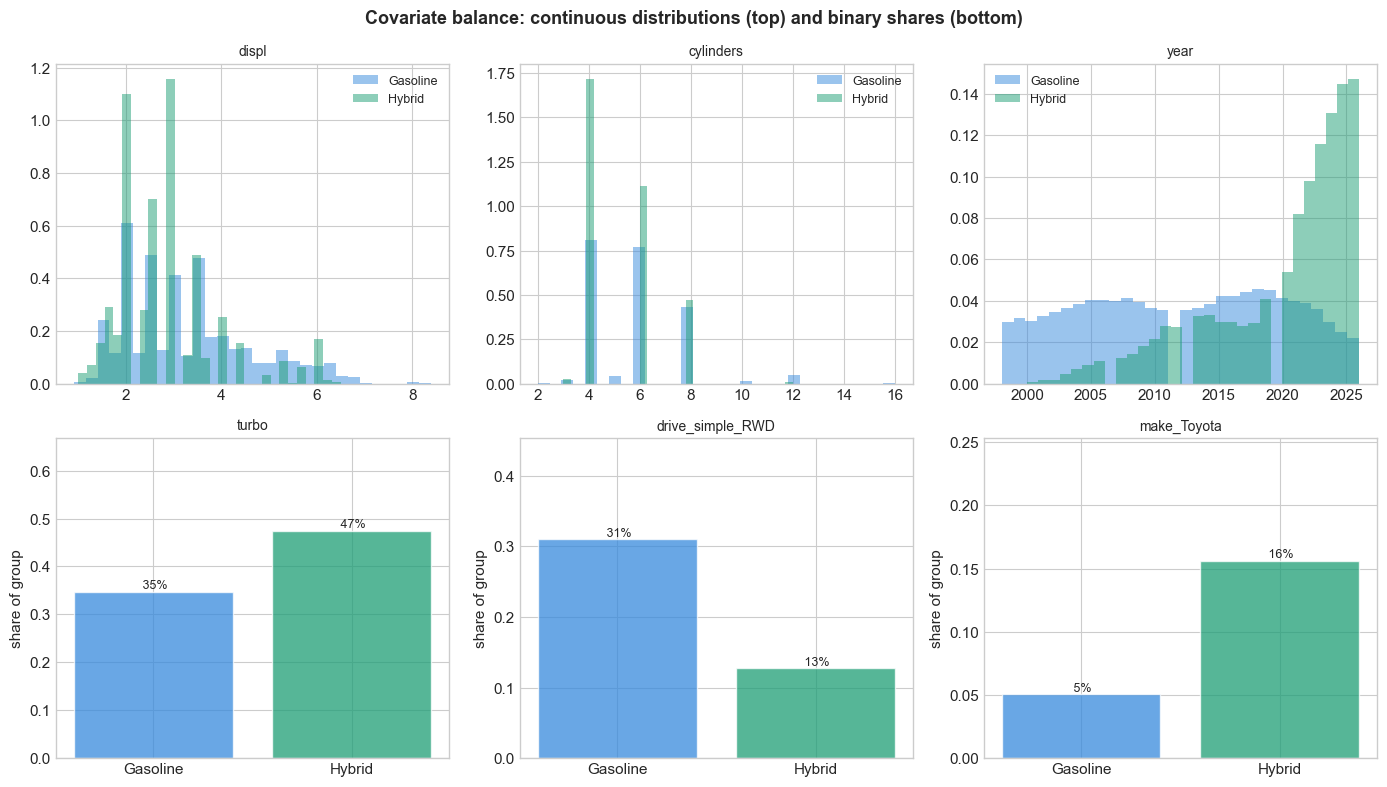

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
# Top row: continuous confounders as density histograms.
for ax, col in zip(axes[0], ['displ', 'cylinders', 'year']):
    for grp, label, color in [(0, 'Gasoline', BLUE), (1, 'Hybrid', GREEN)]:
        ax.hist(Xd_df.loc[T == grp, col], bins=30, alpha=0.5, label=label,
                color=color, density=True)
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=9)
# Bottom row: binary columns as group shares (histograms of 0/1 are unreadable).
for ax, col in zip(axes[1], ['turbo'] + [c for c, _ in cat_smds[:2]]):
    shares = [Xd_df.loc[T == 0, col].mean(), Xd_df.loc[T == 1, col].mean()]
    ax.bar(['Gasoline', 'Hybrid'], shares, color=[BLUE, GREEN], alpha=0.75, edgecolor='white')
    ax.set_ylim(0, min(1, max(shares) * 1.3 + 0.05))
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('share of group')
    for j, v in enumerate(shares):
        ax.text(j, v, f' {v:.0%}', ha='center', va='bottom', fontsize=9)
plt.suptitle('Covariate balance: continuous distributions (top) and binary shares (bottom)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('01_covariate_balance.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Naive comparison and the MPG illusion

This is what you get without any causal reasoning - just compare group means.
We show it both in MPG (familiar, but misleading) and in gallons/100mi (correct).

In [9]:
gp_gas, gp_hyb = Y[T == 0], Y[T == 1]
mpg_gas, mpg_hyb = mpg[T == 0], mpg[T == 1]

naive_ate = gp_hyb.mean() - gp_gas.mean()          # gal/100mi, negative = saves fuel
naive_pct = naive_ate / gp_gas.mean() * 100
naive_mpg = mpg_hyb.mean() - mpg_gas.mean()

print("Naive comparison (no adjustment):")
print(f"  Mean MPG:      Gasoline {mpg_gas.mean():.1f}  vs  Hybrid {mpg_hyb.mean():.1f}"
      f"   -> +{naive_mpg:.1f} MPG (+{naive_mpg/mpg_gas.mean()*100:.0f}%)   <- the 'MPG illusion'")
print(f"  Mean gal/100mi: Gasoline {gp_gas.mean():.2f} vs  Hybrid {gp_hyb.mean():.2f}"
      f"   -> {naive_ate:+.2f} ({naive_pct:+.0f}% fuel)")
print(f"\n  The MPG framing (+{naive_mpg/mpg_gas.mean()*100:.0f}%) overstates the true "
      f"fuel saving ({naive_pct:+.0f}%).")
print("  Both are still BIASED: hybrids are midsize sedans, not pickups/SUVs.")

Naive comparison (no adjustment):
  Mean MPG:      Gasoline 20.9  vs  Hybrid 29.7   -> +8.8 MPG (+42%)   <- the 'MPG illusion'
  Mean gal/100mi: Gasoline 5.04 vs  Hybrid 3.75   -> -1.29 (-26% fuel)

  The MPG framing (+42%) overstates the true fuel saving (-26%).
  Both are still BIASED: hybrids are midsize sedans, not pickups/SUVs.


## 6. Propensity score and the overlap (common-support) sample

P(hybrid | X). We need good overlap (positivity). Because gasoline vehicles that
look nothing like any hybrid (big pickups) carry no counterfactual information,
we restrict all adjusted estimators to the **common-support / overlap** sample.
The resulting estimand is the average effect in the overlap (common-support)
population - not a whole-fleet ATE (not identified here). Matching rows (PSM,
Mahalanobis, within-model) target the ATT. IPW, AIPW, IRM and the forest target
the overlap-sample ATE. OLS and partial-linear DML target a variance-weighted
effect (weights e(1-e), close to the ATO).

The score is **cross-fitted** (out-of-fold, grouped by nameplate) so it is not
overfit in-sample - the same reason we cross-fit the AIPW/DML nuisances.

In [10]:
ps = cross_val_predict(
    cb_clf(), Xd, T, groups=cluster_id,
    cv=GroupKFold(n_splits=5, shuffle=True, random_state=42),
    method='predict_proba')[:, 1]

print("Propensity score (cross-fitted GBM) distribution:")
print(f"  Gasoline: mean={ps[T==0].mean():.4f}, median={np.median(ps[T==0]):.4f}")
print(f"  Hybrid:   mean={ps[T==1].mean():.4f}, median={np.median(ps[T==1]):.4f}")

# Common support (overlap)
ps_min = max(ps[T == 1].min(), ps[T == 0].min())
ps_max = min(ps[T == 1].max(), ps[T == 0].max())
ov = (ps >= ps_min) & (ps <= ps_max)
print(f"\nCommon support: {ov.sum():,} / {len(ps):,} vehicles retained "
      f"({(T[ov]==1).sum():,} hybrid, {(T[ov]==0).sum():,} gasoline)")

# Overlap-sample arrays reused by the adjusted estimators.
Xd_ov = Xd[ov]
T_ov = T[ov]
Y_ov = Y[ov]
ps_ov = ps[ov]
clu_ov = cluster_id[ov]
ov_df = df_clean.loc[ov].reset_index(drop=True)
eps = 0.01   # propensity clip for IPW / AIPW


# % fuel change divides each effect by E[Y(0)] of its own target population,
# estimated as a weighted mean of overlap-sample control outcomes.
def control_mean(w):
    return np.average(Y_ov[T_ov == 0], weights=w[T_ov == 0])


base_ate = control_mean(1 / (1 - np.clip(ps_ov, eps, 1 - eps)))   # IPW, AIPW, IRM, forest
base_vw = control_mean(ps_ov)                                      # OLS, DML (e(1-e) weights)

Propensity score (cross-fitted GBM) distribution:
  Gasoline: mean=0.0417, median=0.0146
  Hybrid:   mean=0.3309, median=0.2941

Common support: 26,003 / 28,764 vehicles retained (1,744 hybrid, 24,259 gasoline)


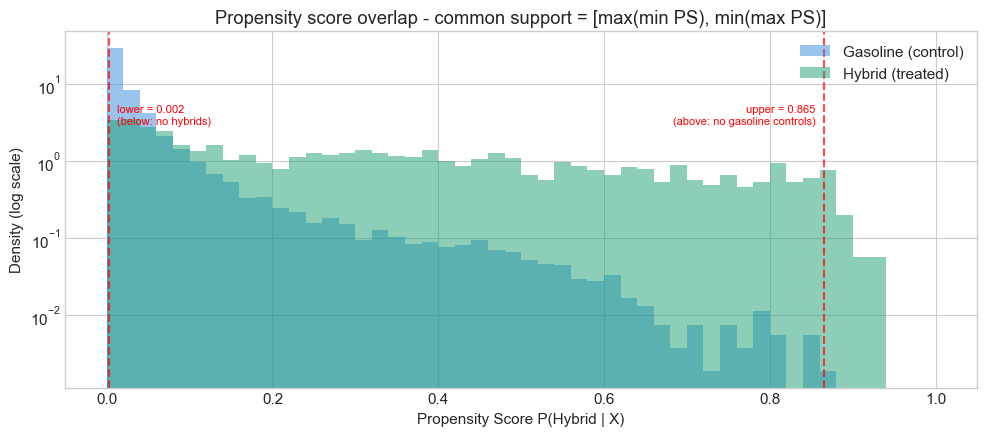

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1, 51)
ax.hist(ps[T == 0], bins=bins, alpha=0.5, label='Gasoline (control)', color=BLUE, density=True)
ax.hist(ps[T == 1], bins=bins, alpha=0.5, label='Hybrid (treated)', color=GREEN, density=True)
# Log y-axis: on a linear one the gasoline spike near PS=0 hides the hybrid mass.
ax.set_yscale('log')
ax.axvline(ps_min, color='red', linestyle='--', alpha=0.7)
ax.axvline(ps_max, color='red', linestyle='--', alpha=0.7)
ytxt = ax.get_ylim()[1] * 0.06
ax.text(ps_min + 0.01, ytxt, f'lower = {ps_min:.3f}\n(below: no hybrids)',
        fontsize=8, color='red', va='bottom', ha='left')
ax.text(ps_max - 0.01, ytxt, f'upper = {ps_max:.3f}\n(above: no gasoline controls)',
        fontsize=8, color='red', va='bottom', ha='right')
ax.set_xlabel('Propensity Score P(Hybrid | X)')
ax.set_ylabel('Density (log scale)')
ax.set_title('Propensity score overlap - common support = [max(min PS), min(max PS)]')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('02_propensity_overlap.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Cluster bootstrap: resample whole nameplates, not rows, so trim/year replicates
# do not fake precision. Returns the percentile CI.
def cluster_boot_ci(clu, stat_fn, n_boot=1000, seed=42, alpha=0.05):
    rng = np.random.RandomState(seed)
    uniq = np.unique(clu)
    idx_by = {c: np.where(clu == c)[0] for c in uniq}
    ests = []
    for _ in range(n_boot):
        drawn = rng.choice(uniq, size=len(uniq), replace=True)
        ests.append(stat_fn(np.concatenate([idx_by[c] for c in drawn])))
    return tuple(np.percentile(ests, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

## 7. OLS regression adjustment (overlap sample, one-hot, clustered SE)

Regress Y on T and one-hot X on the overlap sample. Categoricals enter as dummies
(not as a meaningless ordinal number). Standard errors are clustered by nameplate.

In [13]:
X_ols = sm.add_constant(np.column_stack([T_ov.astype(float), Xd_ov]))
ols = sm.OLS(Y_ov, X_ols).fit(cov_type='cluster', cov_kwds={'groups': clu_ov})
ate_ols = ols.params[1]   # coefficient on T
ci_ols = ols.conf_int()[1]
print("OLS regression adjustment (overlap, cluster-robust SE):")
print(f"  Effect: {ate_ols:+.3f} gal/100mi ({ate_ols/base_vw*100:+.1f}% fuel)")
print(f"  95% CI: [{ci_ols[0]:.3f}, {ci_ols[1]:.3f}]   p = {ols.pvalues[1]:.2e}")

OLS regression adjustment (overlap, cluster-robust SE):
  Effect: -0.730 gal/100mi (-16.1% fuel)
  95% CI: [-0.817, -0.643]   p = 9.16e-61


## 8. Propensity Score Matching (PSM) -> ATT

For each hybrid, find the nearest gasoline vehicle by propensity score (on the
overlap sample). Compare outcomes within matched pairs. CI via cluster bootstrap
over treated nameplates.

In [14]:
def psm_match(t, p):
    """1:1 nearest-neighbour PS matching with replacement -> (treated, matched control) indices."""
    it_, ic_ = np.where(t == 1)[0], np.where(t == 0)[0]
    _, ix = NearestNeighbors(n_neighbors=1).fit(p[ic_].reshape(-1, 1)).kneighbors(
        p[it_].reshape(-1, 1))
    return it_, ic_[ix.ravel()]


def psm_att(rows):
    """ATT on a set of overlap rows. Re-matched on every bootstrap draw; the
    bootstrap is only approximate for NN matching (Abadie & Imbens 2008)."""
    it_, mc_ = psm_match(T_ov[rows], ps_ov[rows])
    return Y_ov[rows][it_].mean() - Y_ov[rows][mc_].mean()


it0, matched0 = psm_match(T_ov, ps_ov)
ate_psm = Y_ov[it0].mean() - Y_ov[matched0].mean()
base_psm = Y_ov[matched0].mean()
ci_psm = cluster_boot_ci(clu_ov, psm_att)

print("Propensity Score Matching (1:1 NN, ATT of overlap-treated):")
print(f"  ATT: {ate_psm:+.3f} gal/100mi ({ate_psm/base_psm*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI (re-matched): [{ci_psm[0]:.3f}, {ci_psm[1]:.3f}]")
print(f"  PS balance: treated {ps_ov[it0].mean():.4f} vs matched {ps_ov[matched0].mean():.4f}")

Propensity Score Matching (1:1 NN, ATT of overlap-treated):
  ATT: -0.864 gal/100mi (-18.8% fuel)
  95% cluster-bootstrap CI (re-matched): [-1.077, -0.661]
  PS balance: treated 0.3217 vs matched 0.3218


## 9. Inverse Probability Weighting (IPW, Hajek normalized)

Weight each observation by the inverse of its propensity score, on the overlap
sample. We report the Hajek (self-normalized) estimator; CI via cluster bootstrap.

In [15]:
def hajek_ate(rows):
    t, y, p = T_ov[rows], Y_ov[rows], np.clip(ps_ov[rows], eps, 1 - eps)
    w1, w0 = t / p, (1 - t) / (1 - p)
    return (w1 * y).sum() / w1.sum() - (w0 * y).sum() / w0.sum()


ate_ipw = hajek_ate(np.arange(len(Y_ov)))
ci_ipw = cluster_boot_ci(clu_ov, hajek_ate)
print("Inverse Probability Weighting (Hajek, overlap):")
print(f"  ATE: {ate_ipw:+.3f} gal/100mi ({ate_ipw/base_ate*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI: [{ci_ipw[0]:.3f}, {ci_ipw[1]:.3f}]")

Inverse Probability Weighting (Hajek, overlap):
  ATE: -0.870 gal/100mi (-17.6% fuel)
  95% cluster-bootstrap CI: [-1.204, -0.565]


## 10. Augmented IPW (Doubly Robust / AIPW) - cross-fitted

Combines outcome regression and propensity weighting; consistent if **either**
model is correct. Nuisances are **cross-fitted with GroupKFold (grouped by
nameplate)** so in-sample overfitting does not shrink residuals and replicate
trims do not leak across folds. CI is the cluster-robust influence-function
interval (cluster sums of *centered* scores).

In [16]:
def crossfit_aipw(X, T, Y, clu, n_splits=5, seed=42):
    n = len(Y)
    mu1 = np.zeros(n)
    mu0 = np.zeros(n)
    psx = np.zeros(n)
    gkf = GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, te in gkf.split(X, groups=clu):
        m1 = cb_reg(seed).fit(X[tr][T[tr] == 1], Y[tr][T[tr] == 1])
        m0 = cb_reg(seed).fit(X[tr][T[tr] == 0], Y[tr][T[tr] == 0])
        pm = cb_clf(seed).fit(X[tr], T[tr])
        mu1[te] = m1.predict(X[te])
        mu0[te] = m0.predict(X[te])
        psx[te] = pm.predict_proba(X[te])[:, 1]
    psx = np.clip(psx, eps, 1 - eps)
    # Per-unit AIPW score (influence function).
    score = (T * (Y - mu1) / psx + mu1) - ((1 - T) * (Y - mu0) / (1 - psx) + mu0)
    ate = score.mean()
    # Cluster-robust SE: sum the centered scores within each cluster.
    se = np.sqrt((np.bincount(clu, weights=score - ate) ** 2).sum()) / len(score)
    return ate, se, mu1 - mu0   # mu1 - mu0 is the cross-fitted T-learner CATE


ate_aipw, se_aipw, cate_ov = crossfit_aipw(Xd_ov, T_ov, Y_ov, clu_ov)
ci_aipw = (ate_aipw - 1.96 * se_aipw, ate_aipw + 1.96 * se_aipw)
print("Augmented IPW (Doubly Robust, cross-fitted, cluster-robust SE):")
print(f"  ATE: {ate_aipw:+.3f} gal/100mi ({ate_aipw/base_ate*100:+.1f}% fuel)")
print(f"  SE: {se_aipw:.3f}   95% CI: [{ci_aipw[0]:.3f}, {ci_aipw[1]:.3f}]")

Augmented IPW (Doubly Robust, cross-fitted, cluster-robust SE):
  ATE: -0.868 gal/100mi (-17.5% fuel)
  SE: 0.040   95% CI: [-0.946, -0.791]


## 11. Double Machine Learning (DML) with CatBoost

Chernozhukov et al. (2018): partial out confounders from both T and Y using
flexible ML, then regress residuals on residuals. Cross-fitting uses GroupKFold
(grouped by nameplate) to prevent overfitting and cross-fold leakage; SE is
cluster-robust. With heterogeneous effects this partial-linear estimator targets
a variance-weighted average (weights e(1-e)), not the ATE.

In [17]:
def dml_estimate(X, T, Y, clu, seed=42, iters=300):
    """Partial-linear DML -> (theta, cluster-robust SE)."""
    rY, rT = np.zeros(len(Y)), np.zeros(len(T))
    gkf = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for tr, te in gkf.split(X, groups=clu):
        rY[te] = Y[te] - cb_reg(seed, iters).fit(X[tr], Y[tr]).predict(X[te])
        rT[te] = T[te] - cb_reg(seed, iters).fit(X[tr], T[tr]).predict(X[te])
    B = np.sum(rT ** 2)
    theta = np.sum(rT * rY) / B
    g = rT * (rY - theta * rT)   # score contributions
    se = np.sqrt((np.bincount(clu, weights=g) ** 2).sum()) / B
    return theta, se


ate_dml, se_dml = dml_estimate(Xd_ov, T_ov.astype(float), Y_ov, clu_ov)
ci_dml = (ate_dml - 1.96 * se_dml, ate_dml + 1.96 * se_dml)
dml_seeds = [ate_dml] + [dml_estimate(Xd_ov, T_ov.astype(float), Y_ov, clu_ov, seed=s)[0]
                         for s in [123, 456]]
print("Double Machine Learning (CatBoost, 5-fold cross-fitting, cluster-robust SE):")
print(f"  Effect: {ate_dml:+.3f} gal/100mi ({ate_dml/base_vw*100:+.1f}% fuel)")
print(f"  SE: {se_dml:.3f}   95% CI: [{ci_dml[0]:.3f}, {ci_dml[1]:.3f}]")
print(f"  Stability across seeds: {np.mean(dml_seeds):.3f} +/- {np.std(dml_seeds):.3f}")

Double Machine Learning (CatBoost, 5-fold cross-fitting, cluster-robust SE):
  Effect: -0.832 gal/100mi (-18.3% fuel)
  SE: 0.039   95% CI: [-0.908, -0.756]
  Stability across seeds: -0.842 +/- 0.007


### Estimand sensitivity: is engine size a confounder or part of the package?

Displacement, cylinders and forced induction are controlled as confounders, but
engine downsizing / turbocharging are partly *alternatives* to hybridization.
Keeping them isolates the effect **holding engine tech fixed** (the main estimate);
dropping all three gives the **total hybrid-package effect** (larger). We report
both so the estimand is explicit rather than implicit.

In [18]:
keep_pkg = [i for i, nm in enumerate(feat_names) if nm not in ('displ', 'cylinders', 'turbo')]
ate_pkg, se_pkg = dml_estimate(Xd_ov[:, keep_pkg], T_ov.astype(float), Y_ov, clu_ov)
print("Estimand sensitivity (DML):")
print(f"  Holding engine size + induction fixed (main):      {ate_dml:+.3f} gal/100mi")
print(f"  Total package effect (drop displ/cylinders/turbo): {ate_pkg:+.3f} gal/100mi (SE {se_pkg:.3f})")

Estimand sensitivity (DML):
  Holding engine size + induction fixed (main):      -0.832 gal/100mi
  Total package effect (drop displ/cylinders/turbo): -0.982 gal/100mi (SE 0.054)


## 12. Within-model exact matching (strongest design)

Compare the **same model** in gasoline and hybrid versions (e.g., Toyota Camry vs
Camry Hybrid). Same chassis, class, manufacturer - almost a natural experiment.
The gasoline twin must share make, base nameplate, drive type, model year and
forced induction; among candidates we take the closest displacement. Hybrids with
no such twin are dropped. CI via cluster bootstrap over nameplates; it treats each
chosen twin as fixed, so it is slightly optimistic.

In [19]:
hybrid_df = df_clean[df_clean['is_hybrid'] == 1]
gas_df = df_clean[df_clean['is_hybrid'] == 0]

pairs = []
for _, row in hybrid_df.iterrows():
    # Exact base nameplate, not a substring: substrings paired Camry Hybrid with Camry Solara.
    gm = gas_df[
        (gas_df['make'] == row['make']) &
        (gas_df['base_model'] == row['base_model']) &
        (gas_df['drive_simple'] == row['drive_simple']) &
        (gas_df['year'] == row['year']) &
        (gas_df['turbo'] == row['turbo'])
    ].copy()
    if len(gm) > 0:
        gm['displ_diff'] = (gm['displ'] - row['displ']).abs()
        best = gm.sort_values(['displ_diff', 'model']).iloc[0]   # model: deterministic tie-break
        pairs.append({
            'cluster_key': row['cluster_key'],
            'make': row['make'], 'model_hybrid': row['model'],
            'model_gas': best['model'], 'year': row['year'],
            'mpg_hybrid': row['comb08'], 'mpg_gas': best['comb08'],
            'gp_hybrid': 100.0 / row['comb08'], 'gp_gas': 100.0 / best['comb08'],
            'gpc_hybrid': 100.0 / row['city08'], 'gpc_gas': 100.0 / best['city08'],
            'gph_hybrid': 100.0 / row['highway08'], 'gph_gas': 100.0 / best['highway08'],
        })

pairs_df = pd.DataFrame(pairs)
pairs_df['gp_diff'] = pairs_df['gp_hybrid'] - pairs_df['gp_gas']       # <0 = saves fuel
pairs_df['gp_pct'] = pairs_df['gp_diff'] / pairs_df['gp_gas'] * 100
pairs_df['city_diff'] = pairs_df['gpc_hybrid'] - pairs_df['gpc_gas']
pairs_df['hwy_diff'] = pairs_df['gph_hybrid'] - pairs_df['gph_gas']
pairs_df['mpg_diff'] = pairs_df['mpg_hybrid'] - pairs_df['mpg_gas']

ate_within = pairs_df['gp_diff'].mean()
base_within = pairs_df['gp_gas'].mean()
ci_within = cluster_boot_ci(
    pd.factorize(pairs_df['cluster_key'])[0],
    lambda rows: pairs_df['gp_diff'].values[rows].mean(),
)

print(f"Exact matched pairs: {len(pairs_df)}  "
      f"({pairs_df['cluster_key'].nunique()} distinct nameplates)")
print("Within-model effect on fuel consumption:")
print(f"  Combined: {ate_within:+.3f} gal/100mi ({ate_within/base_within*100:+.1f}% fuel)")
print(f"  City:     {pairs_df['city_diff'].mean():+.3f} gal/100mi")
print(f"  Highway:  {pairs_df['hwy_diff'].mean():+.3f} gal/100mi")
print(f"  (MPG reference: {pairs_df['mpg_diff'].mean():+.1f} MPG)")
print(f"  95% cluster-bootstrap CI: [{ci_within[0]:.3f}, {ci_within[1]:.3f}]")

Exact matched pairs: 373  (53 distinct nameplates)
Within-model effect on fuel consumption:
  Combined: -1.031 gal/100mi (-24.6% fuel)
  City:     -1.497 gal/100mi
  Highway:  -0.434 gal/100mi
  (MPG reference: +9.3 MPG)
  95% cluster-bootstrap CI: [-1.152, -0.919]


In [20]:
print("\nTop matched pairs (largest fuel saving):\n")
top = (pairs_df.assign(saving=-pairs_df['gp_diff'])
       .nlargest(15, 'saving')[['make', 'model_hybrid', 'model_gas', 'year',
                                 'mpg_gas', 'mpg_hybrid', 'gp_diff', 'gp_pct']])
print(top.to_string(index=False))


Top matched pairs (largest fuel saving):

    make          model_hybrid      model_gas  year  mpg_gas  mpg_hybrid   gp_diff     gp_pct
     GMC Yukon 1500 Hybrid 2WD Yukon 1500 2WD  2008       14          21 -2.380952 -33.333333
 Lincoln        MKZ Hybrid FWD        MKZ FWD  2015       21          40 -2.261905 -47.500000
 Lincoln        MKZ Hybrid FWD        MKZ FWD  2016       21          40 -2.261905 -47.500000
 Lincoln        MKZ Hybrid FWD        MKZ FWD  2011       21          38 -2.130326 -44.736842
 Lincoln        MKZ Hybrid FWD        MKZ FWD  2012       21          38 -2.130326 -44.736842
 Lincoln        MKZ Hybrid FWD        MKZ FWD  2013       22          38 -1.913876 -42.105263
 Lincoln        MKZ Hybrid FWD        MKZ FWD  2014       22          38 -1.913876 -42.105263
   Dodge           Durango HEV    Durango 4WD  2009       15          21 -1.904762 -28.571429
Chrysler             Aspen HEV      Aspen 4WD  2009       15          21 -1.904762 -28.571429
    Ford     Esca

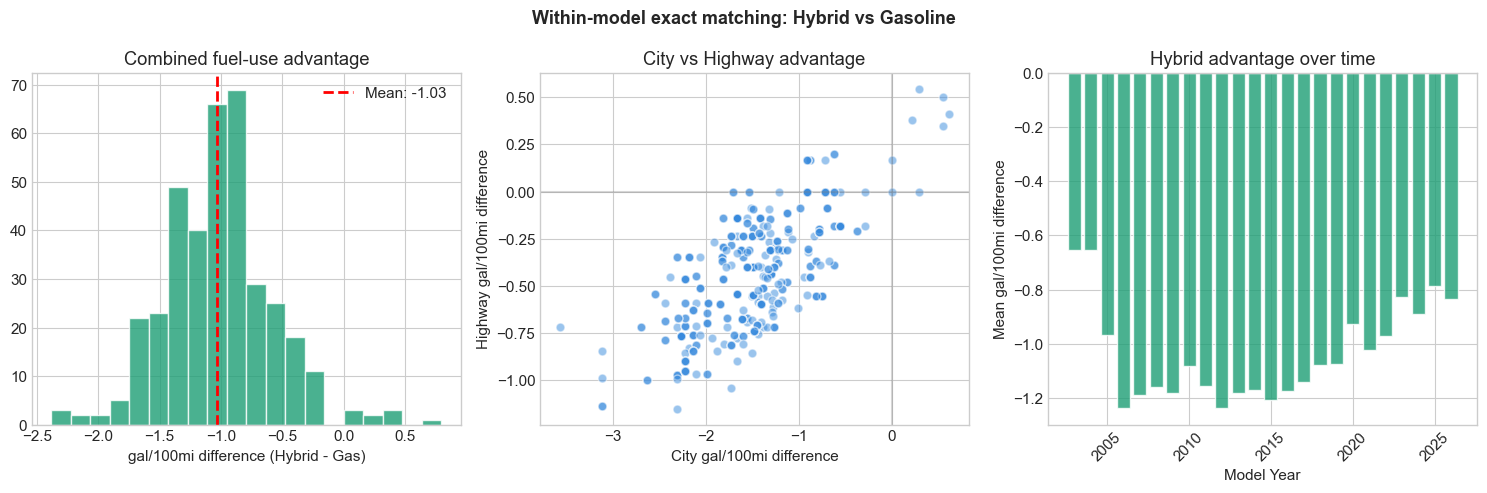

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].hist(pairs_df['gp_diff'], bins=20, color=GREEN, edgecolor='white', alpha=0.8)
axes[0].axvline(ate_within, color='red', linestyle='--', linewidth=2,
                label=f'Mean: {ate_within:+.2f}')
axes[0].set_xlabel('gal/100mi difference (Hybrid - Gas)')
axes[0].set_title('Combined fuel-use advantage')
axes[0].legend()

axes[1].scatter(pairs_df['city_diff'], pairs_df['hwy_diff'],
                alpha=0.5, c=BLUE, edgecolor='white', s=40)
axes[1].axhline(0, color='gray', alpha=0.3)
axes[1].axvline(0, color='gray', alpha=0.3)
axes[1].set_xlabel('City gal/100mi difference')
axes[1].set_ylabel('Highway gal/100mi difference')
axes[1].set_title('City vs Highway advantage')

yearly = pairs_df.groupby('year')['gp_diff'].mean()
axes[2].bar(yearly.index, yearly.values, color=GREEN, edgecolor='white', alpha=0.8)
axes[2].set_xlabel('Model Year')
axes[2].set_ylabel('Mean gal/100mi difference')
axes[2].set_title('Hybrid advantage over time')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Within-model exact matching: Hybrid vs Gasoline', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('03_exact_matching.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Heterogeneous Treatment Effects (CATE) - cross-fitted T-learner

Does the effect vary by class or engine size? The T-learner CATE is mu1(x) - mu0(x)
from the cross-fitted AIPW outcome models (section 10), so it carries no in-sample
optimism. Estimated on the **overlap sample**; groups with fewer than 15 hybrids
are dropped to avoid off-support extrapolation. CATE < 0 means the hybrid burns
less fuel.

In [22]:
MIN_TREATED = 15   # report only subgroups with at least this many hybrids

cate_df = ov_df.assign(
    cate=cate_ov,
    displ_bin=pd.cut(ov_df['displ'], bins=[0, 2, 3, 4, 6, 10], right=False,
                     labels=['<2L', '2-3L', '3-4L', '4-6L', '6L+']))


def cate_by(col):
    g = cate_df.groupby(col, observed=True).agg(
        cate=('cate', 'mean'), n=('cate', 'size'), hybrids=('is_hybrid', 'sum'))
    return g[g['hybrids'] >= MIN_TREATED]


cate_cls = cate_by('vclass_simple').sort_values('cate')
cate_disp = cate_by('displ_bin')
print("CATE (gal/100mi, negative = saves fuel; overlap sample, hybrid-supported groups)\n")
print(cate_cls.round(2).to_string(), '\n')
print(cate_disp.round(2).to_string())

CATE (gal/100mi, negative = saves fuel; overlap sample, hybrid-supported groups)

               cate      n  hybrids
vclass_simple                      
Other         -1.10  12088      885
Wagon         -0.89    851       38
Compact       -0.88   3403      201
Midsize       -0.86   3573      374
Subcompact    -0.78   2062       95
Large         -0.75   1610      104
TwoSeater     -0.42   1485       45 

           cate     n  hybrids
displ_bin                     
<2L       -0.89  2642      240
2-3L      -0.91  8975      687
3-4L      -0.87  7779      563
4-6L      -0.95  5384      192
6L+       -1.36  1223       62


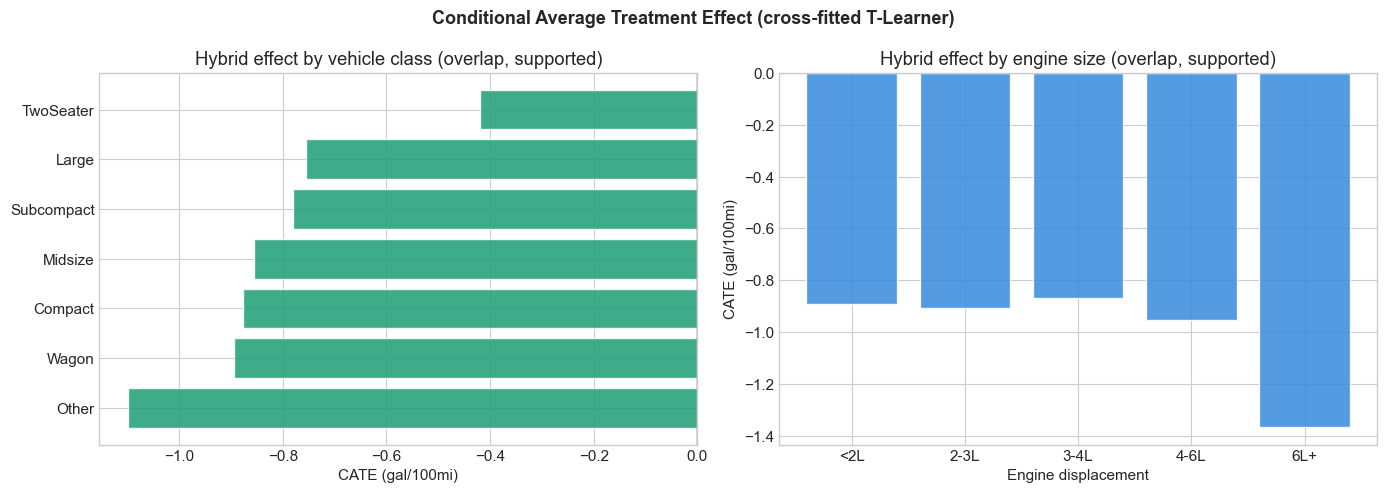

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(cate_cls.index, cate_cls['cate'], color=GREEN, edgecolor='white', alpha=0.85)
axes[0].set_xlabel('CATE (gal/100mi)')
axes[0].set_title('Hybrid effect by vehicle class (overlap, supported)')
axes[0].axvline(0, color='gray', alpha=0.3)

axes[1].bar(cate_disp.index.astype(str), cate_disp['cate'], color=BLUE, edgecolor='white', alpha=0.85)
axes[1].set_xlabel('Engine displacement')
axes[1].set_ylabel('CATE (gal/100mi)')
axes[1].set_title('Hybrid effect by engine size (overlap, supported)')
axes[1].axhline(0, color='gray', alpha=0.3)

plt.suptitle('Conditional Average Treatment Effect (cross-fitted T-Learner)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('04_cate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Summary: all estimators compared

Adjusted estimators are reported in gallons/100mi (negative = less fuel).
IPW and AIPW target the **overlap-sample ATE**; OLS and DML a variance-weighted
effect close to the ATO; matching rows (PSM, within-model) the **ATT**. The naive
row is the full-sample, unadjusted contrast, shown for reference only. Each % uses
E[Y(0)] of the row's own target population as its baseline.

In [24]:
results = pd.DataFrame({
    'Estimator': [
        'Naive (full sample, unadjusted)',
        'OLS adjustment (overlap)',
        'Propensity Score Matching (ATT)',
        'Inverse Probability Weighting',
        'AIPW (cross-fitted, DR)',
        'DML (CatBoost, cross-fit)',
        'Within-model exact matching',
    ],
    'effect': [naive_ate, ate_ols, ate_psm, ate_ipw, ate_aipw, ate_dml, ate_within],
    'CI_low': [np.nan, ci_ols[0], ci_psm[0], ci_ipw[0], ci_aipw[0], ci_dml[0], ci_within[0]],
    'CI_high': [np.nan, ci_ols[1], ci_psm[1], ci_ipw[1], ci_aipw[1], ci_dml[1], ci_within[1]],
    'base': [gp_gas.mean(), base_vw, base_psm, base_ate, base_ate, base_vw, base_within],
})
results['pct_fuel'] = results['effect'] / results['base'] * 100

print("=" * 84)
print("  CAUSAL EFFECT OF HYBRID ON FUEL CONSUMPTION (gal/100mi; negative = saves fuel)")
print("=" * 84)
for _, r in results.iterrows():
    ci = f"[{r['CI_low']:+.2f}, {r['CI_high']:+.2f}]" if pd.notna(r['CI_low']) else "N/A"
    print(f"  {r['Estimator']:34s} effect = {r['effect']:+.2f}  ({r['pct_fuel']:+5.1f}% fuel)  95% CI: {ci}")
print("=" * 84)

  CAUSAL EFFECT OF HYBRID ON FUEL CONSUMPTION (gal/100mi; negative = saves fuel)
  Naive (full sample, unadjusted)    effect = -1.29  (-25.5% fuel)  95% CI: N/A
  OLS adjustment (overlap)           effect = -0.73  (-16.1% fuel)  95% CI: [-0.82, -0.64]
  Propensity Score Matching (ATT)    effect = -0.86  (-18.8% fuel)  95% CI: [-1.08, -0.66]
  Inverse Probability Weighting      effect = -0.87  (-17.6% fuel)  95% CI: [-1.20, -0.56]
  AIPW (cross-fitted, DR)            effect = -0.87  (-17.5% fuel)  95% CI: [-0.95, -0.79]
  DML (CatBoost, cross-fit)          effect = -0.83  (-18.3% fuel)  95% CI: [-0.91, -0.76]
  Within-model exact matching        effect = -1.03  (-24.6% fuel)  95% CI: [-1.15, -0.92]


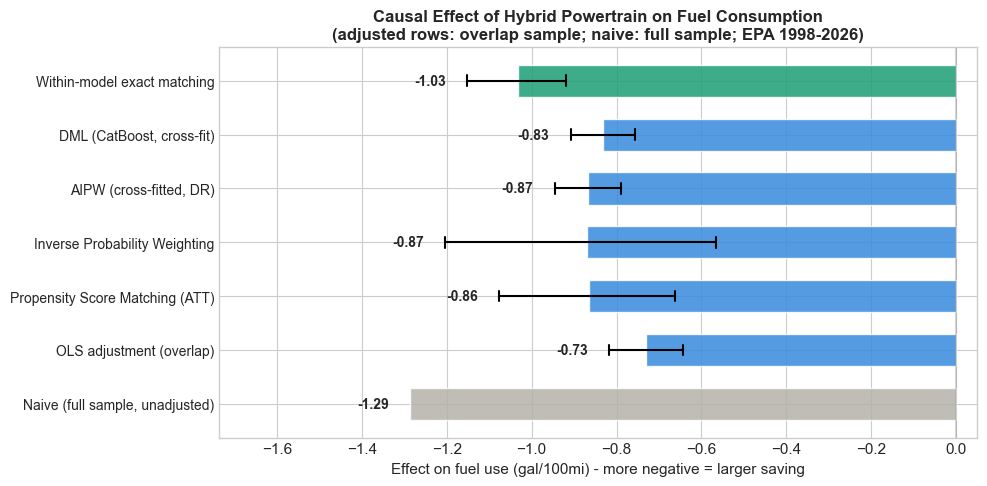

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = range(len(results))
colors = [GREY] + [BLUE] * 5 + [GREEN]
ax.barh(y_pos, results['effect'], color=colors, edgecolor='white', alpha=0.85, height=0.6)
for i, r in results.iterrows():
    if pd.notna(r['CI_low']):
        ax.plot([r['CI_low'], r['CI_high']], [i, i], color='black', linewidth=1.5, zorder=5)
        ax.plot([r['CI_low']]*2, [i-0.1, i+0.1], color='black', linewidth=1.5)
        ax.plot([r['CI_high']]*2, [i-0.1, i+0.1], color='black', linewidth=1.5)
    lab_x = (r['CI_low'] if pd.notna(r['CI_low']) else r['effect']) - 0.05
    ax.text(lab_x, i, f"{r['effect']:+.2f}", va='center', ha='right',
            fontsize=10, fontweight='bold')
ax.set_xlim(min(results['effect'].min(), results['CI_low'].min()) - 0.45, 0.05)
ax.set_yticks(y_pos)
ax.set_yticklabels(results['Estimator'], fontsize=10)
ax.set_xlabel('Effect on fuel use (gal/100mi) - more negative = larger saving', fontsize=11)
ax.set_title('Causal Effect of Hybrid Powertrain on Fuel Consumption\n'
             f'(adjusted rows: overlap sample; naive: full sample; EPA {YR})',
             fontsize=12, fontweight='bold')
ax.axvline(0, color='gray', alpha=0.3)
plt.tight_layout()
plt.savefig('05_estimator_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. Sensitivity analysis: Rosenbaum bounds

How strong would an unobserved confounder need to be to explain away the result?
Applied to the within-model matched pairs (per-nameplate fuel saving).

In [26]:
def rosenbaum_bounds(diff, gammas):
    """Wilcoxon signed-rank Rosenbaum bounds (diff > 0 = hybrid saves fuel).
    Zero differences are dropped before ranking, as usual for signed-rank tests."""
    diff = diff[diff != 0]
    ranks = stats.rankdata(np.abs(diff))
    T_obs = np.sum(ranks[diff > 0])
    out = []
    for gamma in gammas:
        p_plus = gamma / (1 + gamma)
        E_T = np.sum(ranks * p_plus)
        Var_T = np.sum(ranks ** 2 * p_plus * (1 - p_plus))
        z = (T_obs - E_T) / np.sqrt(Var_T)
        out.append({'Gamma': gamma, 'p_upper': 1 - stats.norm.cdf(z)})
    return pd.DataFrame(out)


# One mean saving per nameplate: pairs within a nameplate (years, drivetrains) are
# not independent. Saving > 0 means the hybrid uses less fuel.
saving = -pairs_df.groupby('cluster_key')['gp_diff'].mean().values
gammas = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]
bounds = rosenbaum_bounds(saving, gammas)
print(f"Rosenbaum Sensitivity Analysis (within-model, {len(saving)} nameplates):")
print("  Gamma = odds ratio of unmeasured confounding\n")
for _, r in bounds.iterrows():
    sig = "***" if r['p_upper'] < 0.001 else "**" if r['p_upper'] < 0.01 else \
          "*" if r['p_upper'] < 0.05 else "ns"
    print(f"  Gamma={r['Gamma']:5.1f}:  p_upper={r['p_upper']:.4f}  {sig}")
g_max = bounds.loc[bounds['p_upper'] < 0.05, 'Gamma'].max()
print(f"\n  Significant at 5% up to Gamma={g_max:.1f} (tested up to {gammas[-1]:.1f})")

Rosenbaum Sensitivity Analysis (within-model, 53 nameplates):
  Gamma = odds ratio of unmeasured confounding

  Gamma=  1.0:  p_upper=0.0000  ***
  Gamma=  1.5:  p_upper=0.0000  ***
  Gamma=  2.0:  p_upper=0.0000  ***
  Gamma=  2.5:  p_upper=0.0001  ***
  Gamma=  3.0:  p_upper=0.0003  ***
  Gamma=  4.0:  p_upper=0.0014  **
  Gamma=  5.0:  p_upper=0.0041  **
  Gamma=  6.0:  p_upper=0.0085  **
  Gamma=  8.0:  p_upper=0.0215  *
  Gamma= 10.0:  p_upper=0.0383  *

  Significant at 5% up to Gamma=10.0 (tested up to 10.0)


## 16. Improvement 1/8 - Alternative outcome scales (fuel, CO2)

gal/100mi is the right *scale*, but decision-makers think in L/100km, annual fuel,
and annual CO2. We translate the DML effect into those units and re-estimate the
effect directly on tailpipe CO2 (g/mi) as a policy-relevant secondary outcome.

In [27]:
GAL_TO_L = 3.785411784
MI_TO_KM = 1.609344
MI_PER_YR = 15000
KG_CO2_PER_GAL = 8.887  # EPA, gasoline

l_per_100km = ate_dml * GAL_TO_L / MI_TO_KM
ann_gal = ate_dml / 100 * MI_PER_YR
ann_co2_fuel = ann_gal * KG_CO2_PER_GAL   # kg/year

co2_all = df_clean['co2TailpipeGpm'].values.astype(float)
ate_co2, se_co2 = dml_estimate(Xd_ov, T_ov.astype(float), co2_all[ov], clu_ov)

print("Hybrid effect expressed on multiple scales (DML point estimate):")
print(f"  Fuel:  {ate_dml:+.2f} gal/100mi  =  {l_per_100km:+.2f} L/100km")
print(f"  Annual fuel (15k mi/yr): {ann_gal:+.0f} gallons/year")
print(f"  Annual CO2 (via fuel):   {ann_co2_fuel:+.0f} kg/year")
print(f"  Direct DML on tailpipe CO2: {ate_co2:+.1f} g/mi "
      f"(={ate_co2*MI_PER_YR/1000:+.0f} kg/year, SE={se_co2:.1f})")

Hybrid effect expressed on multiple scales (DML point estimate):
  Fuel:  -0.83 gal/100mi  =  -1.96 L/100km
  Annual fuel (15k mi/yr): -125 gallons/year
  Annual CO2 (via fuel):   -1109 kg/year
  Direct DML on tailpipe CO2: -74.5 g/mi (=-1118 kg/year, SE=3.4)


## 17. Improvement 2/8 - Flexible functional form for the OLS baseline

The linear-in-year, linear-in-displacement OLS is a strong assumption. We refit
with **year as fixed effects** and quadratic displacement/cylinders. If the ATE is
stable, the linear baseline was not driving the result.

In [28]:
flex = pd.concat([
    pd.DataFrame({'displ': ov_df['displ'], 'displ2': ov_df['displ'] ** 2,
                  'cyl': ov_df['cylinders'], 'cyl2': ov_df['cylinders'] ** 2,
                  'turbo': ov_df['turbo']}),
    pd.get_dummies(ov_df['year'].astype(int), prefix='yr', drop_first=True).astype(float),
    Xd_df.loc[ov, feat_names[len(num_cov):]].reset_index(drop=True),
], axis=1)
X_flex = sm.add_constant(np.column_stack([T_ov.astype(float), flex.values]))
ols_flex = sm.OLS(Y_ov, X_flex).fit(cov_type='cluster', cov_kwds={'groups': clu_ov})
ci_flex = ols_flex.conf_int()[1]
print("Flexible OLS (year fixed effects + quadratic displ/cyl, cluster-robust):")
print(f"  Effect: {ols_flex.params[1]:+.3f} gal/100mi   95% CI: [{ci_flex[0]:.3f}, {ci_flex[1]:.3f}]")
print(f"  (linear-form OLS was {ate_ols:+.3f}) -> effect is {'stable' if abs(ols_flex.params[1]-ate_ols)<0.15 else 'sensitive'}")

Flexible OLS (year fixed effects + quadratic displ/cyl, cluster-robust):
  Effect: -0.786 gal/100mi   95% CI: [-0.862, -0.711]
  (linear-form OLS was -0.730) -> effect is stable


## 18. Improvement 3/8 - Caliper + Mahalanobis matching with a Love plot

The 1:1 PS match had no caliper and only checked PS balance. Here each hybrid is
matched to the gasoline vehicle with the smallest **Mahalanobis distance on the
numeric covariates**, among those within a caliper on the PS logit (0.2 x SD,
Austin 2011). Hybrids with no control inside the caliper are dropped. The Love
plot compares the matched hybrids against all controls (before) and their twins
(after).

Mahalanobis + caliper matching: 1744/1744 hybrids matched (caliper=0.300 on PS logit)
  ATT: -0.714 gal/100mi (-16.0% fuel)
  95% cluster-bootstrap CI (re-matched): [-0.814, -0.594]


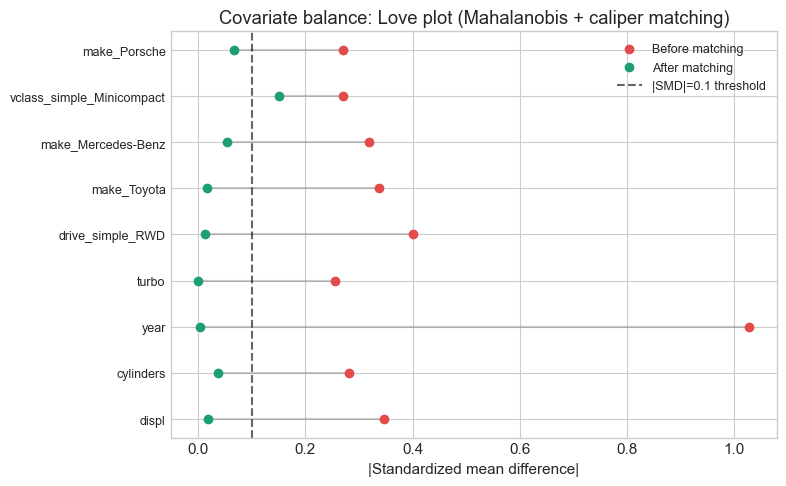

  Mean |SMD|: before=0.390 -> after=0.040


In [29]:
covs = ov_df[num_cov].values.astype(float)
# Whiten with the Cholesky factor of the inverse covariance (VI = L L^T), so plain
# Euclidean distance equals Mahalanobis distance.
L = np.linalg.cholesky(np.linalg.inv(np.cov(covs.T)))
with np.errstate(all='ignore'):   # spurious FP warning from Accelerate BLAS on macOS
    covs_w = covs @ L
logit_ps = np.log(ps_ov / (1 - ps_ov))
caliper = 0.2 * logit_ps.std()


def maha_match(rows):
    """Nearest Mahalanobis control within the PS-logit caliper -> (treated, control) rows."""
    t, c, lp = T_ov[rows], covs_w[rows], logit_ps[rows]
    it_, ic_ = np.where(t == 1)[0], np.where(t == 0)[0]
    ic_ = ic_[np.argsort(lp[ic_])]   # sorted by logit PS, so each caliper window is a slice
    lo = np.searchsorted(lp[ic_], lp[it_] - caliper, side='left')
    hi = np.searchsorted(lp[ic_], lp[it_] + caliper, side='right')
    tr, ctl = [], []
    for i, a, b in zip(it_, lo, hi):
        if b > a:
            win = ic_[a:b]
            tr.append(i)
            ctl.append(win[np.argmin(((c[win] - c[i]) ** 2).sum(axis=1))])
    return rows[tr], rows[ctl]


def maha_att(rows):
    it_, mc_ = maha_match(rows)
    return Y_ov[it_].mean() - Y_ov[mc_].mean()


it_ok, cand_ok = maha_match(np.arange(len(Y_ov)))
ate_maha = Y_ov[it_ok].mean() - Y_ov[cand_ok].mean()
ci_maha = cluster_boot_ci(clu_ov, maha_att)
print(f"Mahalanobis + caliper matching: {len(it_ok)}/{T_ov.sum()} hybrids matched "
      f"(caliper={caliper:.3f} on PS logit)")
print(f"  ATT: {ate_maha:+.3f} gal/100mi "
      f"({ate_maha/Y_ov[cand_ok].mean()*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI (re-matched): [{ci_maha[0]:.3f}, {ci_maha[1]:.3f}]")

# Balance of the same matched hybrids against all controls (before) and their twins (after).
bal_cols = num_cov + [c for c, _ in cat_smds[:5]]
ov_full = Xd_df.loc[ov].reset_index(drop=True)
ic_all = np.where(T_ov == 0)[0]
smd_before, smd_after = [], []
for c in bal_cols:
    v = ov_full[c]
    smd_before.append(abs(smd(v.iloc[it_ok], v.iloc[ic_all])))
    smd_after.append(abs(smd(v.iloc[it_ok], v.iloc[cand_ok])))

fig, ax = plt.subplots(figsize=(8, 5))
yp = np.arange(len(bal_cols))
ax.scatter(smd_before, yp, color=RED, label='Before matching', zorder=3)
ax.scatter(smd_after, yp, color=GREEN, label='After matching', zorder=3)
for i in yp:
    ax.plot([smd_after[i], smd_before[i]], [i, i], color='gray', alpha=0.4, zorder=1)
ax.axvline(0.1, color='black', linestyle='--', alpha=0.6, label='|SMD|=0.1 threshold')
ax.set_yticks(yp)
ax.set_yticklabels(bal_cols, fontsize=9)
ax.set_xlabel('|Standardized mean difference|')
ax.set_title('Covariate balance: Love plot (Mahalanobis + caliper matching)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('06_love_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"  Mean |SMD|: before={np.mean(smd_before):.3f} -> after={np.mean(smd_after):.3f}")

## 19. Improvement 4/8 - Overlap weights (ATO)

Instead of a hard common-support cut plus IPW, overlap weights (Li, Morgan &
Zaslavsky 2018) smoothly down-weight units with little overlap: w = 1-e for
treated, e for control. The estimand is the effect in the overlap population
(ATO), with no tuning. With a logistic PS these weights balance covariate means
exactly; with CatBoost the balance is approximate. Computed on the **full** sample.

In [30]:
def ato_estimate(rows):
    t, y, e = T[rows], Y[rows], ps[rows]
    return (np.average(y[t == 1], weights=1 - e[t == 1])
            - np.average(y[t == 0], weights=e[t == 0]))


ate_ato = ato_estimate(np.arange(len(Y)))
base_ato = np.average(Y[T == 0], weights=ps[T == 0])
ci_ato = cluster_boot_ci(cluster_id, ato_estimate)
print("Overlap weights (ATO, full sample):")
print(f"  ATO: {ate_ato:+.3f} gal/100mi ({ate_ato/base_ato*100:+.1f}% fuel)")
print(f"  95% cluster-bootstrap CI: [{ci_ato[0]:.3f}, {ci_ato[1]:.3f}]")

Overlap weights (ATO, full sample):
  ATO: -0.858 gal/100mi (-18.9% fuel)
  95% cluster-bootstrap CI: [-1.048, -0.656]


## 20. Improvement 5/8 - Library estimators (DoubleML IRM, EconML Causal Forest)

Replace the hand-rolled AIPW/DML with battle-tested implementations that carry
Neyman-orthogonal scores, proper cross-fitting and analytic inference: DoubleML's
interactive regression model (IRM, doubly-robust ATE, made cluster-robust here)
and EconML's CausalForestDML. For the forest we report its doubly-robust ATE
(`ate_`); that CI is row-level, not cluster-robust, so it is too narrow.

In [31]:
# Nameplate clusters make the IRM CI cluster-robust. Seed the global RNG, which
# IRM uses for its fold splits.
np.random.seed(42)
dml_data = DoubleMLClusterData.from_arrays(Xd_ov, Y_ov, T_ov, cluster_vars=clu_ov.reshape(-1, 1))
irm = DoubleMLIRM(dml_data, ml_g=cb_reg(), ml_m=cb_clf(), n_folds=5)
irm.fit()
ci_irm = irm.confint().values.ravel()
print("DoubleML IRM (doubly-robust ATE, CatBoost nuisances, cluster-robust):")
print(f"  ATE: {irm.coef[0]:+.3f} gal/100mi   95% CI: [{ci_irm[0]:.3f}, {ci_irm[1]:.3f}]")

cf = CausalForestDML(
    model_y=cb_reg(), model_t=cb_clf(),
    discrete_treatment=True, cv=GroupKFold(n_splits=3), n_estimators=300,
    min_samples_leaf=10, n_jobs=1, random_state=42)
cf.fit(Y_ov, T_ov, X=Xd_ov, groups=clu_ov)
ate_cf = cf.ate_[0]
ci_cf = [v[0] for v in cf.ate__inference().conf_int()]
print("EconML CausalForestDML (doubly-robust ATE, row-level CI):")
print(f"  ATE: {ate_cf:+.3f} gal/100mi   95% CI: [{ci_cf[0]:.3f}, {ci_cf[1]:.3f}]")

DoubleML IRM (doubly-robust ATE, CatBoost nuisances, cluster-robust):
  ATE: -0.845 gal/100mi   95% CI: [-0.928, -0.763]


EconML CausalForestDML (doubly-robust ATE, row-level CI):
  ATE: -0.979 gal/100mi   95% CI: [-1.019, -0.938]


## 21. Improvement 6/8 - Refutation / falsification tests

Following the DoWhy refutation framework, we stress-test the design with a lighter
DML (150 iterations instead of 300):
- **Placebo treatment**: permute the treatment - a real design should give ~0.
- **Random common cause**: add an irrelevant covariate - estimate should not move.
- **Data subset**: re-estimate on random subsamples - estimate should be stable.
- **Negative-control outcome**: hybridness should not affect passenger volume.

In [32]:
def fast_dml(X, T, Y, groups, seed=42):
    return dml_estimate(X, T, Y, groups, seed=seed, iters=150)[0]


real_theta = fast_dml(Xd_ov, T_ov.astype(float), Y_ov, clu_ov)

rng = np.random.RandomState(0)
placebo = np.array([fast_dml(Xd_ov, rng.permutation(T_ov).astype(float), Y_ov, clu_ov, seed=s)
                    for s in range(8)])

Xd_rcc = np.column_stack([Xd_ov, rng.normal(size=len(Y_ov))])
theta_rcc = fast_dml(Xd_rcc, T_ov.astype(float), Y_ov, clu_ov)

subset = []
for s in range(6):
    idx = rng.choice(len(Y_ov), size=int(0.8 * len(Y_ov)), replace=False)
    subset.append(fast_dml(Xd_ov[idx], T_ov[idx].astype(float), Y_ov[idx], clu_ov[idx], seed=s))
subset = np.array(subset)

# Negative control: passenger volume should not depend on the powertrain. Caveats:
# pv4 > 0 keeps mostly 4-door cars, EPA car classes are defined by interior volume
# (so conditioning on class makes pv4 partly mechanical), and batteries can take
# cabin space.
pv4 = df_clean['pv4'].values.astype(float)
nco_mask = ov & (pv4 > 0)
theta_nco, se_nco = dml_estimate(Xd[nco_mask], T[nco_mask].astype(float),
                                 pv4[nco_mask], cluster_id[nco_mask])
z_nco = theta_nco / se_nco
d_main = abs(real_theta) / Y_ov.std()
d_nco = abs(theta_nco) / pv4[nco_mask].std()

print("Refutation / falsification tests:")
print(f"  Real effect (fast DML):  {real_theta:+.3f} gal/100mi")
print(f"  Placebo treatment:       {placebo.mean():+.3f} +/- {placebo.std():.3f}  "
      f"(should be ~0; |real| beyond placebo range: {abs(real_theta) > np.abs(placebo).max()})")
print(f"  Random common cause:     {theta_rcc:+.3f}  (should ~= real)")
print(f"  Data subset (80%):       {subset.mean():+.3f} +/- {subset.std():.3f}  (should ~= real)")
print(f"  Negative-control (pv4):  effect={theta_nco:+.2f} cu ft (SE {se_nco:.2f}, z={z_nco:+.1f}); "
      f"standardized {d_nco:.2f} vs main {d_main:.2f}")
print(f"  Negative control {'passes (|z| < 2)' if abs(z_nco) < 2 else 'fails (|z| >= 2): residual confounding possible'}")

Refutation / falsification tests:
  Real effect (fast DML):  -0.845 gal/100mi
  Placebo treatment:       -0.004 +/- 0.006  (should be ~0; |real| beyond placebo range: True)
  Random common cause:     -0.845  (should ~= real)
  Data subset (80%):       -0.858 +/- 0.008  (should ~= real)
  Negative-control (pv4):  effect=+1.53 cu ft (SE 0.44, z=+3.5); standardized 0.18 vs main 0.70
  Negative control fails (|z| >= 2): residual confounding possible


## 22. Improvement 7/8 - E-value sensitivity (VanderWeele & Ding)

The E-value is the minimum strength of association (on the risk-ratio scale) that
an unmeasured confounder would need with *both* treatment and outcome to explain
away the effect. For a continuous outcome we map the standardized effect to an
approximate RR (RR ~= exp(0.91 x d)). The CI E-value uses the bound nearest zero
and is 1 when the CI crosses zero.

In [33]:
def e_value(d):
    rr = np.exp(0.91 * abs(d))
    return rr + np.sqrt(rr * (rr - 1))


sd_y = Y_ov.std()
d_point = ate_dml / sd_y
ci_near_null = ci_dml[np.argmin(np.abs(ci_dml))]
e_ci = 1.0 if ci_dml[0] < 0 < ci_dml[1] else e_value(ci_near_null / sd_y)
print("E-value sensitivity (primary DML estimate):")
print(f"  Standardized effect d = {d_point:.3f}  ->  E-value (point) = {e_value(d_point):.2f}")
print(f"  For the CI bound nearest null ({ci_near_null:+.2f}) -> E-value = {e_ci:.2f}")
print(f"  Interpretation: an unmeasured confounder would need RR ~ {e_value(d_point):.1f}"
      f" with both hybrid-status and fuel use to explain away the effect.")

E-value sensitivity (primary DML estimate):
  Standardized effect d = -0.690  ->  E-value (point) = 3.15
  For the CI bound nearest null (-0.76) -> E-value = 2.94
  Interpretation: an unmeasured confounder would need RR ~ 3.2 with both hybrid-status and fuel use to explain away the effect.


## 23. Improvement 8/8 - Rated vs real-world caveat

All estimates use EPA **rated** fuel economy. Real-world tests show hybrids fall
short of their EPA label by ~10% vs ~2% for conventional cars (Consumer Reports),
because EPA cycles favor the conditions where hybrids excel. So the real-world
advantage is somewhat smaller. Illustrative bracket applied to the within-model
pairs (hybrid +10% fuel, gasoline +2% fuel in the real world):

In [34]:
rw_hyb = pairs_df['gp_hybrid'] * 1.10
rw_gas = pairs_df['gp_gas'] * 1.02
rw_diff = (rw_hyb - rw_gas).mean()
rw_pct = rw_diff / rw_gas.mean() * 100
print("Rated vs real-world (illustrative, within-model pairs):")
print(f"  Rated:      {ate_within:+.3f} gal/100mi ({ate_within/base_within*100:+.1f}% fuel)")
print(f"  Real-world: {rw_diff:+.3f} gal/100mi ({rw_pct:+.1f}% fuel)  <- ~10%/2% shortfall applied")
print("  The sign and rough magnitude survive; the point estimate shrinks modestly.")

Rated vs real-world (illustrative, within-model pairs):
  Rated:      -1.031 gal/100mi (-24.6% fuel)
  Real-world: -0.799 gal/100mi (-18.7% fuel)  <- ~10%/2% shortfall applied
  The sign and rough magnitude survive; the point estimate shrinks modestly.


## 24. Extended estimator comparison (with improvements)

In [35]:
extra = pd.DataFrame({
    'Estimator': ['Mahalanobis + caliper (ATT)', 'Overlap weights (ATO)',
                  'DoubleML IRM (library)', 'Causal Forest (EconML)'],
    'effect': [ate_maha, ate_ato, irm.coef[0], ate_cf],
    'CI_low': [ci_maha[0], ci_ato[0], ci_irm[0], ci_cf[0]],
    'CI_high': [ci_maha[1], ci_ato[1], ci_irm[1], ci_cf[1]],
    'base': [Y_ov[cand_ok].mean(), base_ato, base_ate, base_ate],
})
extra['pct_fuel'] = extra['effect'] / extra['base'] * 100
ext = pd.concat([results, extra], ignore_index=True)

print("=" * 84)
print("  EXTENDED COMPARISON: original + improvement estimators (gal/100mi)")
print("=" * 84)
for _, r in ext.iterrows():
    ci = f"[{r['CI_low']:+.2f}, {r['CI_high']:+.2f}]" if pd.notna(r['CI_low']) else "N/A"
    print(f"  {r['Estimator']:34s} effect = {r['effect']:+.2f}  ({r['pct_fuel']:+5.1f}% fuel)  95% CI: {ci}")
print("=" * 84)

  EXTENDED COMPARISON: original + improvement estimators (gal/100mi)
  Naive (full sample, unadjusted)    effect = -1.29  (-25.5% fuel)  95% CI: N/A
  OLS adjustment (overlap)           effect = -0.73  (-16.1% fuel)  95% CI: [-0.82, -0.64]
  Propensity Score Matching (ATT)    effect = -0.86  (-18.8% fuel)  95% CI: [-1.08, -0.66]
  Inverse Probability Weighting      effect = -0.87  (-17.6% fuel)  95% CI: [-1.20, -0.56]
  AIPW (cross-fitted, DR)            effect = -0.87  (-17.5% fuel)  95% CI: [-0.95, -0.79]
  DML (CatBoost, cross-fit)          effect = -0.83  (-18.3% fuel)  95% CI: [-0.91, -0.76]
  Within-model exact matching        effect = -1.03  (-24.6% fuel)  95% CI: [-1.15, -0.92]
  Mahalanobis + caliper (ATT)        effect = -0.71  (-16.0% fuel)  95% CI: [-0.81, -0.59]
  Overlap weights (ATO)              effect = -0.86  (-18.9% fuel)  95% CI: [-1.05, -0.66]
  DoubleML IRM (library)             effect = -0.85  (-17.1% fuel)  95% CI: [-0.93, -0.76]
  Causal Forest (EconML)        

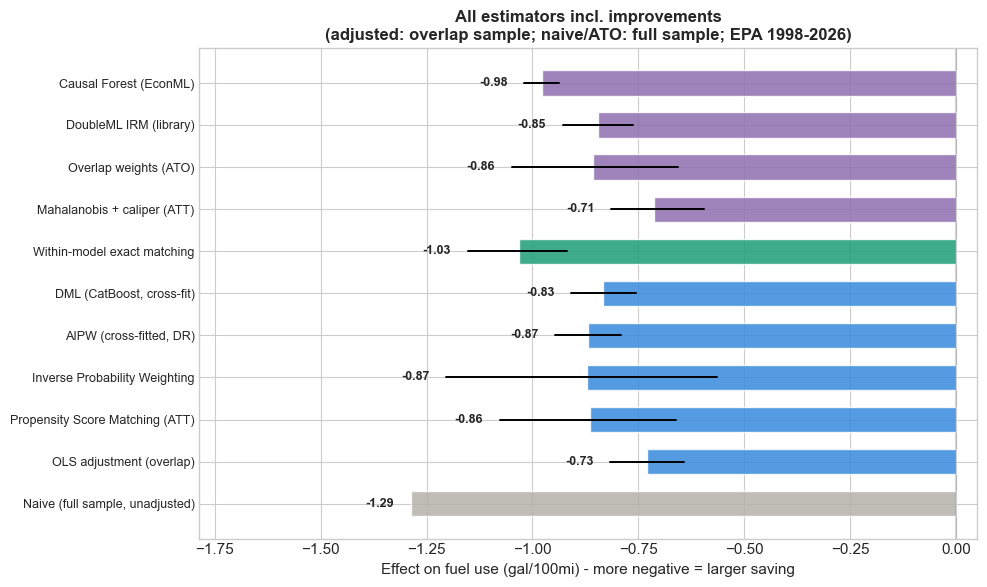

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))
yp = range(len(ext))
colors = [GREY] + [BLUE] * 5 + [GREEN] + ['#8E6FB0'] * 4
ax.barh(yp, ext['effect'], color=colors, edgecolor='white', alpha=0.85, height=0.6)
for i, r in ext.iterrows():
    if pd.notna(r['CI_low']):
        ax.plot([r['CI_low'], r['CI_high']], [i, i], color='black', linewidth=1.4, zorder=5)
    lab_x = (r['CI_low'] if pd.notna(r['CI_low']) else r['effect']) - 0.04
    ax.text(lab_x, i, f"{r['effect']:+.2f}", va='center', ha='right',
            fontsize=9, fontweight='bold')
ax.set_xlim(min(ext['effect'].min(), ext['CI_low'].min()) - 0.5, 0.05)
ax.set_yticks(list(yp))
ax.set_yticklabels(ext['Estimator'], fontsize=9)
ax.set_xlabel('Effect on fuel use (gal/100mi) - more negative = larger saving')
ax.set_title('All estimators incl. improvements\n'
             f'(adjusted: overlap sample; naive/ATO: full sample; EPA {YR})',
             fontsize=12, fontweight='bold')
ax.axvline(0, color='gray', alpha=0.3)
plt.tight_layout()
plt.savefig('07_extended_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Key takeaways

1. **Measure fuel, not MPG.** In MPG the naive gap is +8.8 MPG (+42%). MPG is the
   reciprocal of consumption, so this overstates the saving. In gallons/100mi the
   same data show hybrids use 26% less fuel.

2. **Adjustment shrinks the gap.** IPW, AIPW, DML, IRM, PSM and ATO land at -0.83
   to -0.87 gal/100mi (about -17% to -19% fuel). OLS and Mahalanobis matching are
   smaller in magnitude (-0.73, -0.71). The causal forest (-0.98) and within-model
   twins (-1.03) are larger. The naive -1.29 is outside this range.

3. **The estimand is the overlap effect, not a whole-fleet ATE.** Hybrids and
   gasoline vehicles overlap only in part of the covariate space (big pickups have
   no hybrid counterpart), so a population ATE is not identified. We restrict to
   common support; matching rows target the ATT.

4. **Uncertainty is clustered.** Rows are clustered by nameplate, nuisance models
   are cross-fitted with GroupKFold, and every CI except the causal forest's is
   cluster-robust. The CIs reflect 2,724 nameplates, not 28,764 rows.

5. **Heterogeneity.** In the within-model pairs, city savings are about 3.5x
   highway (-1.50 vs -0.43 gal/100mi). That fits regenerative braking and
   engine-off idling in stop-and-go driving. By class (T-learner, overlap sample),
   two-seaters save least (-0.42, mostly mild-hybrid sports cars); the other
   classes range from -0.75 to -1.10. By engine size the effect is flat near -0.9
   below 6L and larger for 6L+ (-1.36, 62 hybrids).

6. **Robustness.** Within-model matching (same nameplate, drive, model year and
   induction) agrees in sign and rough size with the model-based estimators, but
   covers only 373 hybrids from 53 nameplates. Its per-nameplate Rosenbaum bound
   stays significant up to Gamma = 10. Placebo, random-common-cause and subset
   checks pass. The negative control fails: hybrids show +1.5 cu ft passenger
   volume (z = 3.5), so some residual body/packaging confounding is possible.

7. **Effect depends on the data vintage.** On the MY1998-2026 window the adjusted
   effect is -0.71 to -1.03 gal/100mi; on an older MY2015 snapshot it was about
   -1.1 to -1.2. Two reasons: (a) the modern fleet is more efficient, so absolute
   gaps shrink, and (b) 43% of hybrid rows are tagged "Mild Hybrid" in `eng_dscr`.
   Mild hybrids save far less fuel and dilute the treatment. Splitting full vs
   mild hybrids is left as future work.